# 1. Introduction

**Objective:**
- Explore and understand the clinical characteristics of patients in the dataset
- Identify relationships between clinical variables and mortality outcomes
- Visualize distributions, trends, and correlations among features

**About the Dataset:** 
- The dataset has 13 columns, but only 12 predictor features. `DEATH_EVENT` is the target
- These are patients with heart failure, and the dataset records whether they died during the follow-up period

# 2. Importing Libraries

In [2]:
# standard libraries
import warnings

# numeric libraries
import numpy as np
import pandas as pd

# plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# configurations
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

plt.style.use('ggplot')
%matplotlib inline

sns.set_theme()

# 3. Data Acquisition

In [3]:
df = pd.read_csv('/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv')

# 4. Initial Data Inspection

It is better to deal with irregularities in the data before analysis as it may cause issues if exists in the long run. \
In this section,
- Sample count
- Features count
- NaN/NULL values
- Duplicate values
- First five features to get an abstract idea of the dataset
- Information regarding the dataset
- Descriptive statistics 

In [4]:
print("No of samples: ", df.shape[0])
print("No of features:", df.shape[1])
print("NaN values count:", df.isna().sum().sum())
print("Null values count:", df.isnull().sum().sum())
print("Duplicate values:", df.duplicated().any())

No of samples:  299
No of features: 13
NaN values count: 0
Null values count: 0
Duplicate values: False


In [5]:
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.00,0,582,0,20,1,265000.00,1.90,130,1,0,4,1
1,55.00,0,7861,0,38,0,263358.03,1.10,136,1,0,6,1
2,65.00,0,146,0,20,0,162000.00,1.30,129,1,1,7,1
3,50.00,1,111,0,20,0,210000.00,1.90,137,1,0,7,1
4,65.00,1,160,1,20,0,327000.00,2.70,116,0,0,8,1


In [6]:
numerical = [
    'age','creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 
    # 'time'
]
categorical = [
    'anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking',
    #'DEATH_EVENT'
]

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [8]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26,0.32
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61,0.47
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00,0.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00,0.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00,0.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00,1.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00,1.00


### Observations:
1. Most people in the dataset with heart related conditions are around 60 years old
2. There are more registered male patients than female patients
3. The average platelet count is 263358.03
4. The patient age range is (40,95)

# 5. Exploratory Data Analysis
We now look into data to uncover interesting facts and patterns that may cause heart failure 

## 5.1  Univariate Analysis
We look at each feature alone to learn about its distribution

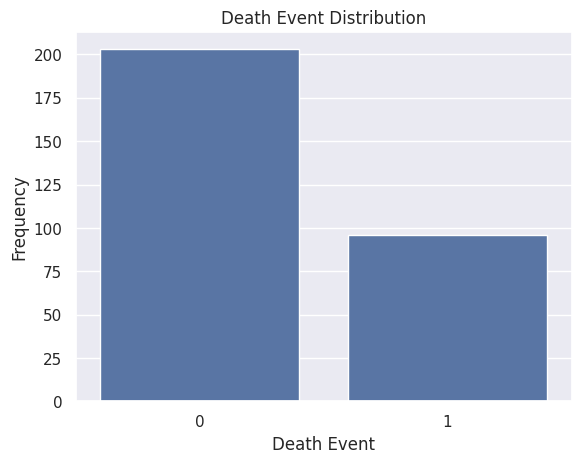

In [9]:
sns.countplot(x='DEATH_EVENT', data=df)
plt.xlabel('Death Event')
plt.ylabel('Frequency')
plt.title("Death Event Distribution")
plt.show()

In [10]:
survivors = df[df['DEATH_EVENT'] == 0].shape[0]
deceased = df[df['DEATH_EVENT'] == 1].shape[0]
total_patients = df.shape[0]

print(f"Survivors: {survivors/total_patients * 100:.2f}%")
print(f"Deceased : {deceased/total_patients * 100:.2f}%")

Survivors: 67.89%
Deceased : 32.11%


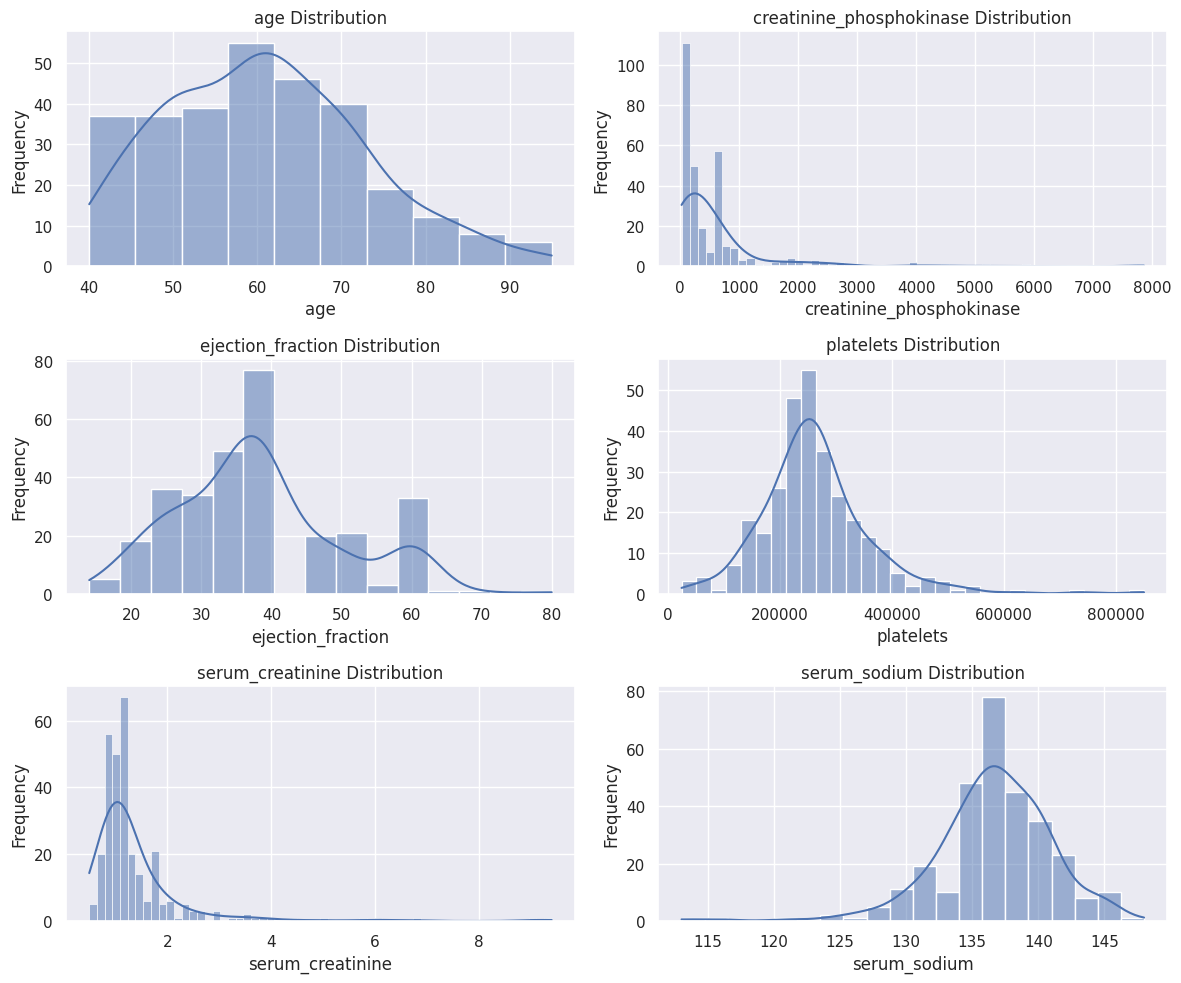

In [11]:
fig, ax = plt.subplots(3, 2, figsize=(12, 10)) 

axes = ax.flatten()

for idx, each in enumerate(numerical):
    sns.histplot(df[each], kde=True ,ax=axes[idx])
    axes[idx].set_xlabel(f"{each}")
    axes[idx].set_ylabel("Frequency")
    axes[idx].set_title(f"{each} Distribution")
plt.tight_layout()
plt.show()


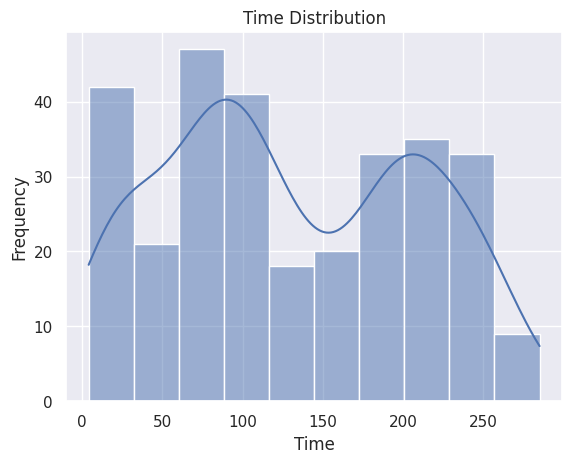

In [12]:
sns.histplot(df['time'], kde=True)
plt.xlabel("Time")
plt.ylabel("Frequency")
plt.title("Time Distribution")
plt.show()

In [13]:
df[categorical].head()

,anaemia,diabetes,high_blood_pressure,sex,smoking
0,0,0,1,1,0
1,0,0,0,1,0
2,0,0,0,1,1
3,1,0,0,1,0
4,1,1,0,0,0


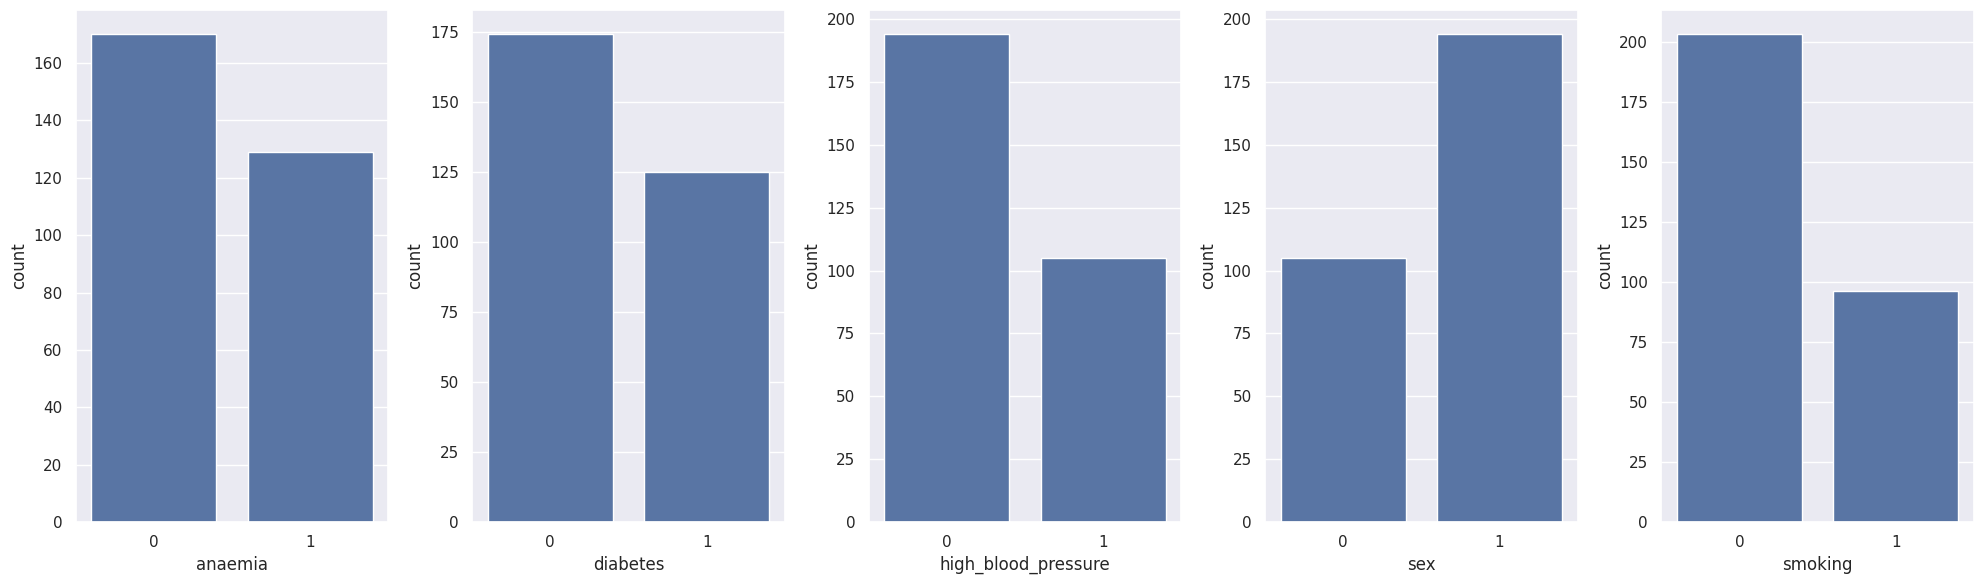

In [31]:
fig, ax = plt.subplots(1, 5, figsize=(20,6))
for idx, each in enumerate(categorical):
    sns.countplot(x=df[each], ax=ax[idx])
plt.tight_layout()
plt.show()

### Observations

1. From the dataset 67.89% of patient survived during the recorded follow-up period
2. The age distribution has a slightly right-skewed tail, with most patient records concentrated between 50 and 70 years.
3. Most patients have relatively low CPK values (below 1,000). The distribution is heavily right-skewed due to a few extremely high CPK values.
4. Most ejection fraction values lie between 25 and 40, with a secondary concentration around 60. The distribution is not symmetric and has multiple peaks.
5. The platelet distribution is slightly right-skewed, with most observations concentrated between 200,000 and 350,000.
6. Most patients have serum creatinine values below 2. The distribution is heavily right-skewed, with a few extremely high values.
7. Most serum sodium values lie between 135 and 140. The distribution approximately follows a normal distribution.

## 5.2  Bivariate Analysis

In [15]:
df[numerical].head()

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium
0,75.00,582,20,265000.00,1.90,130
1,55.00,7861,38,263358.03,1.10,136
2,65.00,146,20,162000.00,1.30,129
3,50.00,111,20,210000.00,1.90,137
4,65.00,160,20,327000.00,2.70,116


In [16]:
age_hf = df.groupby(['DEATH_EVENT'])['age'].describe()
age_hf

,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.00,58.76,10.64,40.00,50.00,60.00,65.00,90.00
1,96.00,65.22,13.21,42.00,55.00,65.00,75.00,95.00


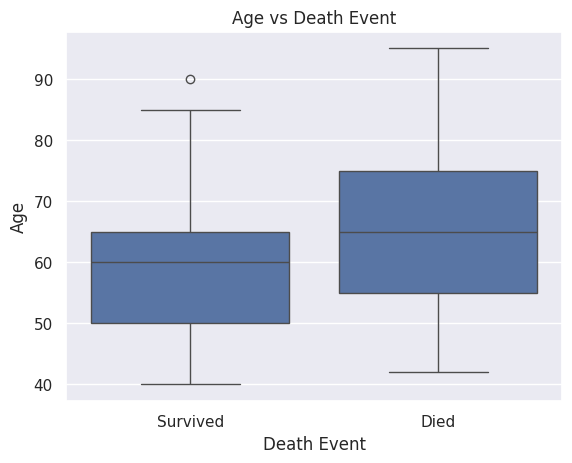

In [17]:
sns.boxplot(y='age', x='DEATH_EVENT', data=df)
plt.xticks([0,1],['Survived', 'Died'])
plt.xlabel("Death Event")
plt.ylabel("Age")
plt.title("Age vs Death Event")
plt.show()

In [18]:
platelet_hf = df.groupby(['DEATH_EVENT'])['platelets'].describe()
platelet_hf

,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.00,266657.49,97531.20,25100.00,219500.00,263000.00,302000.00,850000.00
1,96.00,256381.04,98525.68,47000.00,197500.00,258500.00,311000.00,621000.00


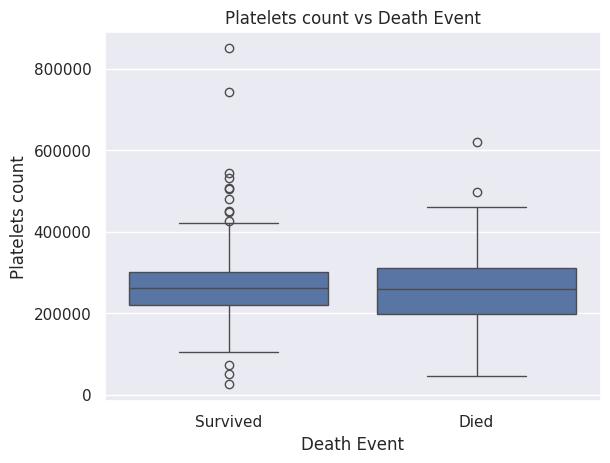

In [19]:
sns.boxplot(y='platelets', x='DEATH_EVENT', data=df)
plt.xticks([0,1],['Survived', 'Died'])
plt.xlabel("Death Event")
plt.ylabel("Platelets count")
plt.title("Platelets count vs Death Event")
plt.show()

In [20]:
df.groupby(['DEATH_EVENT'])['ejection_fraction'].describe()

,count,mean,std,min,25%,50%,75%,max
DEATH_EVENT,,,,,,,,
0,203.00,40.27,10.86,17.00,35.00,38.00,45.00,80.00
1,96.00,33.47,12.53,14.00,25.00,30.00,38.00,70.00


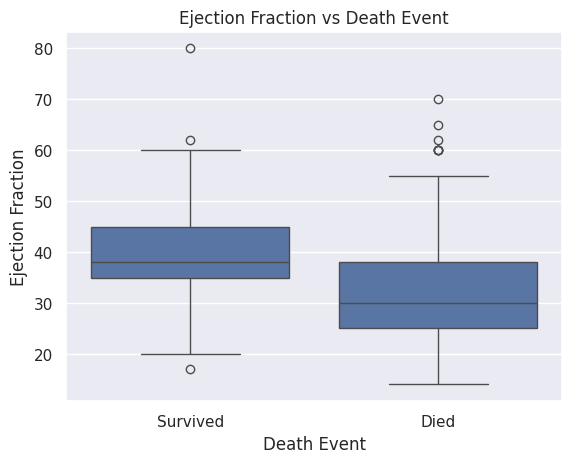

In [21]:
sns.boxplot(y='ejection_fraction', x='DEATH_EVENT', data=df)
plt.xticks([0,1],['Survived', 'Died'])
plt.xlabel("Death Event")
plt.ylabel("Ejection Fraction")
plt.title("Ejection Fraction vs Death Event")
plt.show()

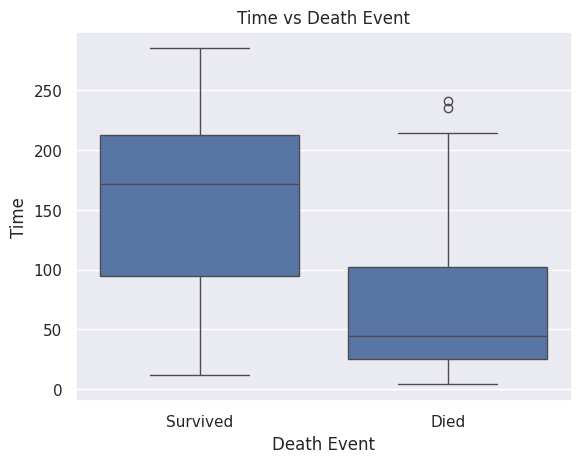

In [22]:
sns.boxplot(y='time', x='DEATH_EVENT', data=df)
plt.xticks([0,1],['Survived', 'Died'])
plt.xlabel("Death Event")
plt.ylabel("Time")
plt.title("Time vs Death Event")
plt.show()

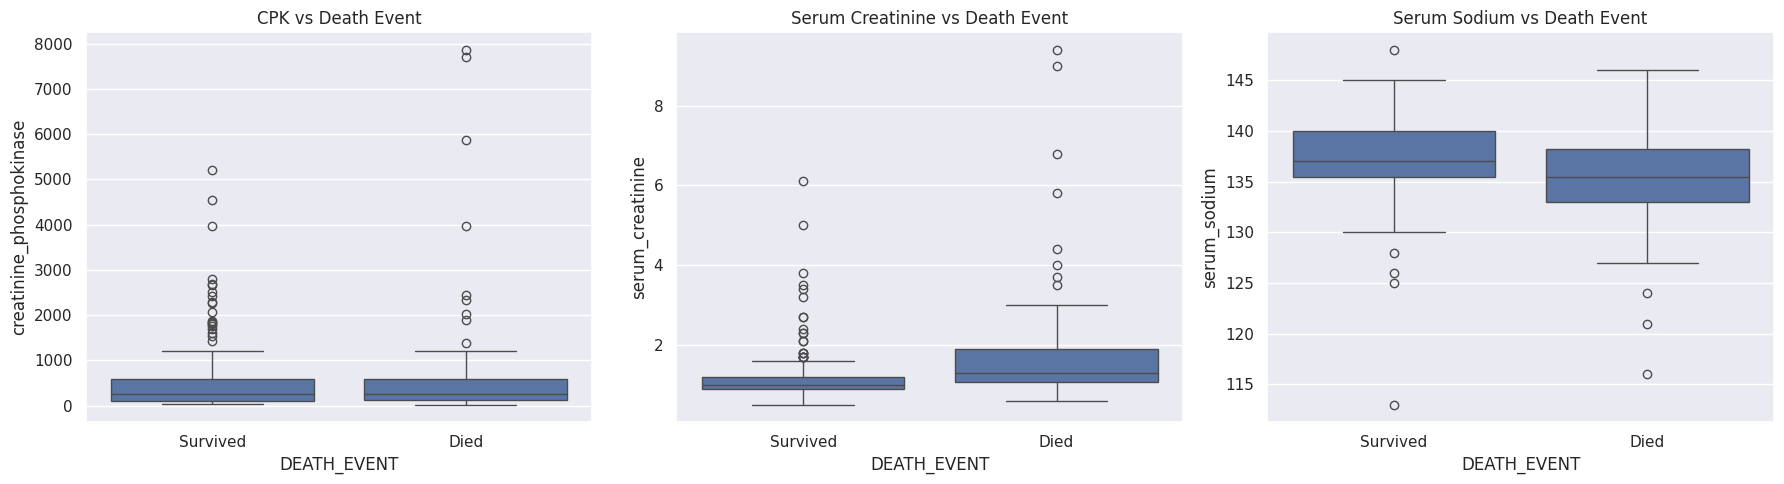

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='DEATH_EVENT', y='creatinine_phosphokinase', ax=axes[0])
axes[0].set_title('CPK vs Death Event')
axes[0].set_xticks([0,1],['Survived', 'Died'])

sns.boxplot(data=df, x='DEATH_EVENT', y='serum_creatinine', ax=axes[1])
axes[1].set_title('Serum Creatinine vs Death Event')
axes[1].set_xticks([0,1],['Survived', 'Died'])

sns.boxplot(data=df, x='DEATH_EVENT', y='serum_sodium', ax=axes[2])
axes[2].set_title('Serum Sodium vs Death Event')
axes[2].set_xticks([0,1],['Survived', 'Died'])

plt.tight_layout()
plt.show()

In [24]:
print("Mortality Rates: ")
for each in categorical:
    print(df.groupby(each)['DEATH_EVENT'].mean() * 100)
    print("")

Mortality Rates: 
anaemia
0   29.41
1   35.66
Name: DEATH_EVENT, dtype: float64

diabetes
0   32.18
1   32.00
Name: DEATH_EVENT, dtype: float64

high_blood_pressure
0   29.38
1   37.14
Name: DEATH_EVENT, dtype: float64

sex
0   32.38
1   31.96
Name: DEATH_EVENT, dtype: float64

smoking
0   32.51
1   31.25
Name: DEATH_EVENT, dtype: float64



### Observations
1. Age, ejection fraction, and time has some noticeable association with mortality
2. Serum Creatinine and Serum Sodium has some association with mortality
3. CPK and platelets has little to no association with mortality
4. The mortality rates are nearly same for diabetes, sex and smoking which contribute less to mortality
5. Anaemia and high blood pressure show higher observed mortality rates among the patients with these conditions compared with those without them

## 5.3  Multivariate Analysis

In [25]:
numerical.extend(['time','DEATH_EVENT'])
df_corr = df[numerical].corr()
df_corr

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,DEATH_EVENT
age,1.00,-0.08,0.06,-0.05,0.16,-0.05,-0.22,0.25
creatinine_phosphokinase,-0.08,1.00,-0.04,0.02,-0.02,0.06,-0.01,0.06
ejection_fraction,0.06,-0.04,1.00,0.07,-0.01,0.18,0.04,-0.27
platelets,-0.05,0.02,0.07,1.00,-0.04,0.06,0.01,-0.05
serum_creatinine,0.16,-0.02,-0.01,-0.04,1.00,-0.19,-0.15,0.29
serum_sodium,-0.05,0.06,0.18,0.06,-0.19,1.00,0.09,-0.20
time,-0.22,-0.01,0.04,0.01,-0.15,0.09,1.00,-0.53
DEATH_EVENT,0.25,0.06,-0.27,-0.05,0.29,-0.20,-0.53,1.00


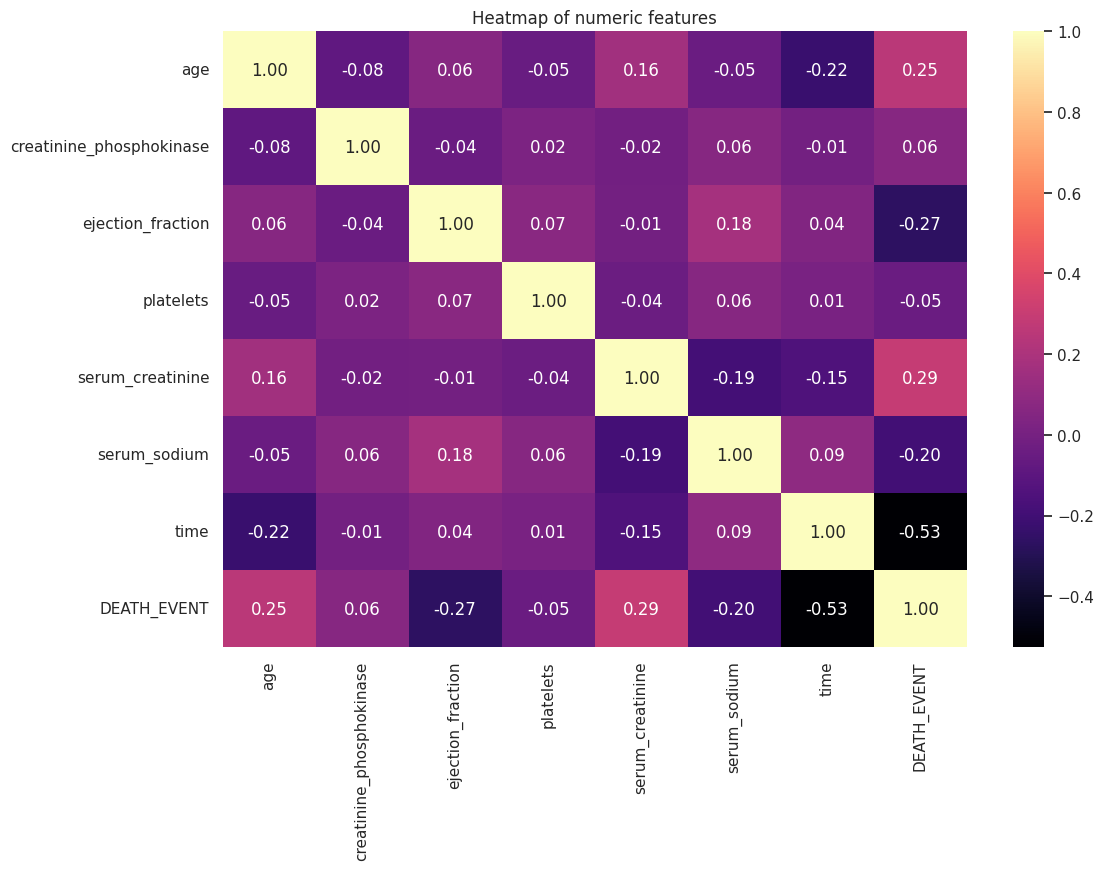

In [29]:
plt.figure(figsize=(12,8))
sns.heatmap(
    data=df_corr,
    cmap='magma',
    fmt='.2f',
    annot=True,
)
plt.title("Heatmap of numeric features")
plt.show()

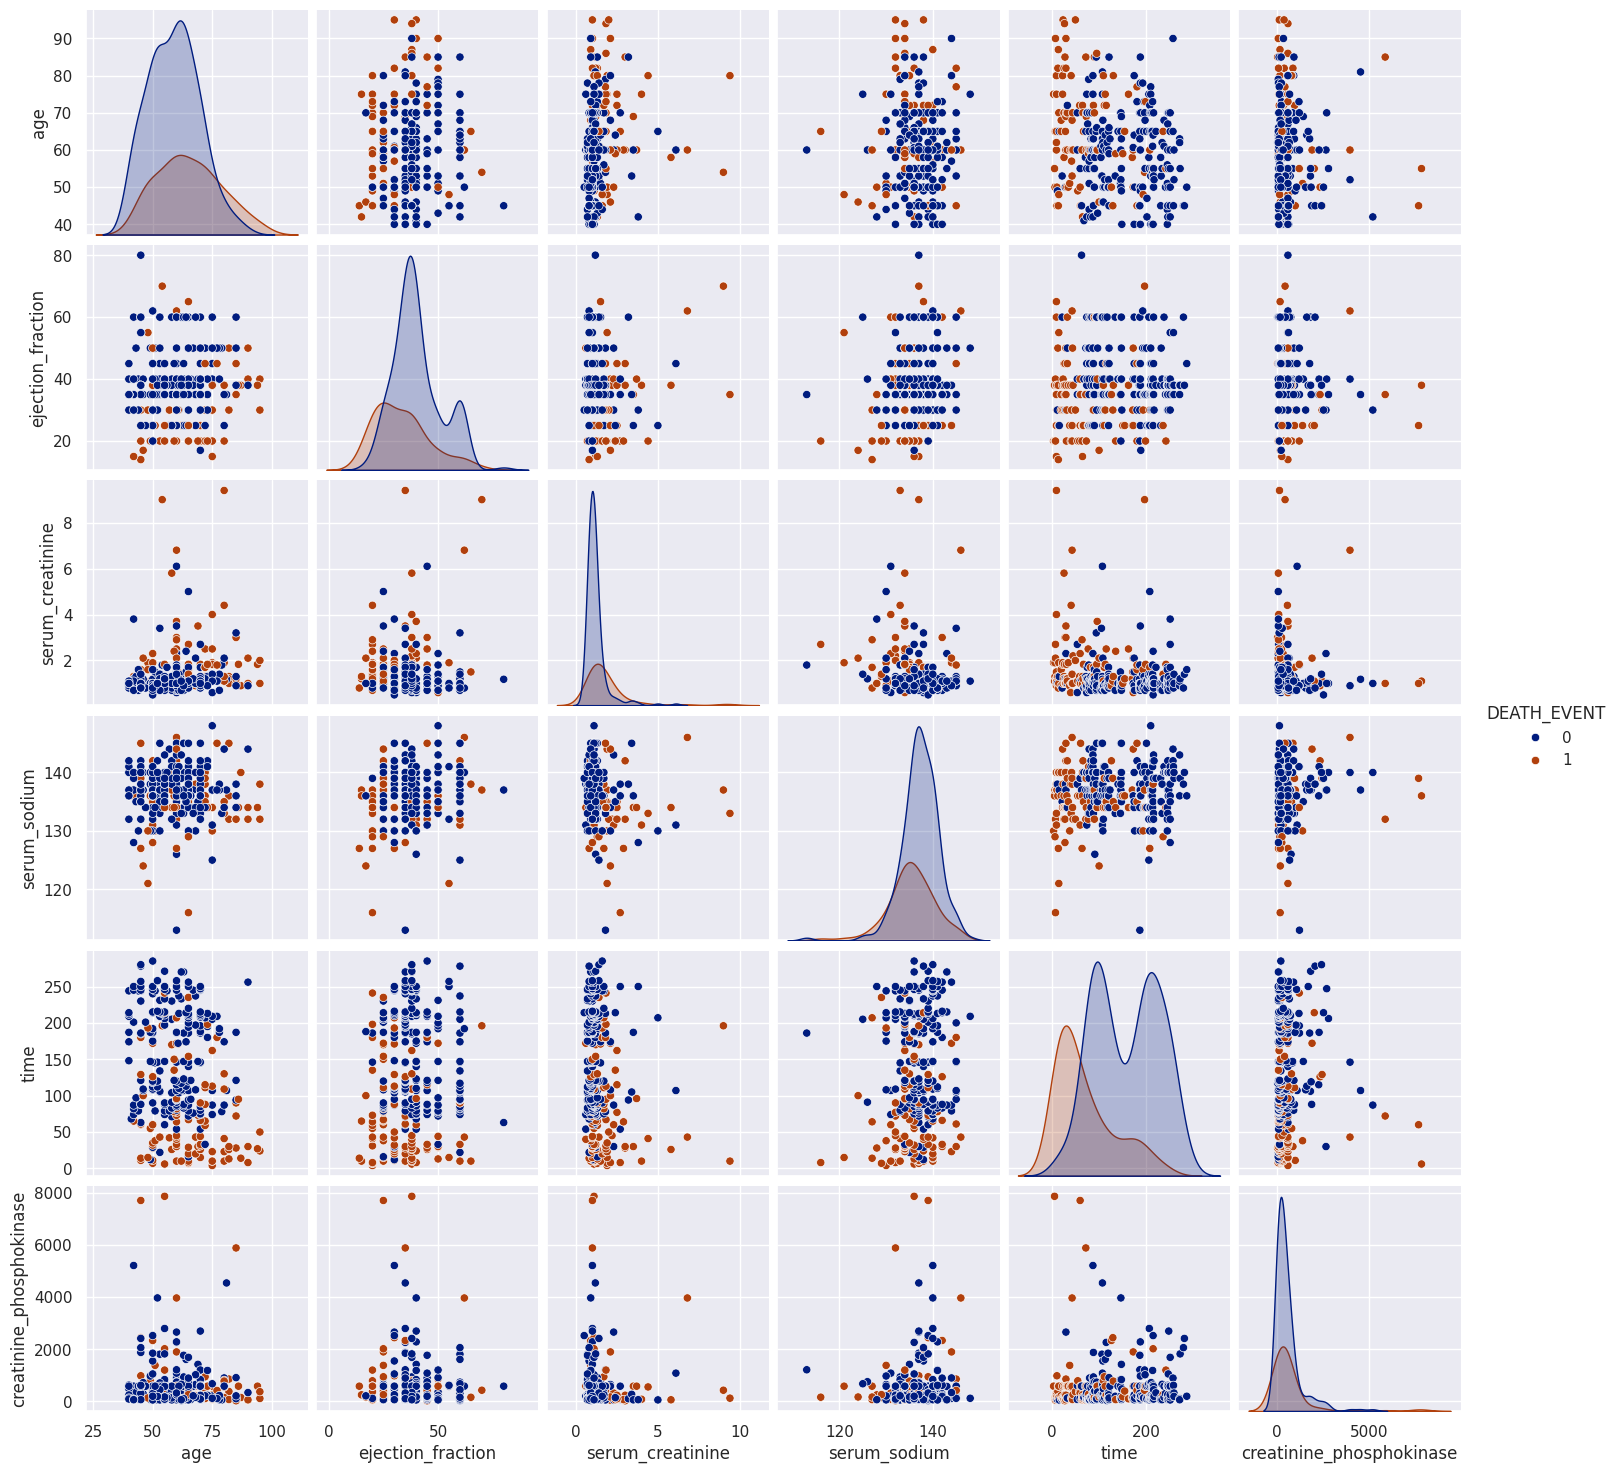

In [27]:
sns.pairplot(
    df[
        [
            "age",
            "ejection_fraction",
            "serum_creatinine",
            "serum_sodium",
            "time",
            "creatinine_phosphokinase",
            "DEATH_EVENT",
        ]
    ],
    hue="DEATH_EVENT",
    palette="dark", 
)

plt.show()

### Observations:
1. The correlation heatmap indicates that most numerical predictors have weak pairwise linear correlations. However, follow-up duration shows a moderate negative correlation with DEATH_EVENT.
2. Pairplot analysis supports the observations from bivariate analysis. Age, ejection fraction, serum creatinine and follow-up duration show noticeable differences between mortality groups, although considerable overlap exists between the distributions.
3. Follow-up duration is a key feature in understanding recorded mortality outcomes. Patients who died generally had shorter observed follow-up periods.

# 6. Key Takeaways
The exploratory data analysis identifies age, ejection fraction and serum creatinine as numerical variables showing noticeable associations with mortality. Anaemia and high blood pressure also exhibit differences in observed mortality rates. Serum sodium shows a weaker association, while CPK, platelet count, diabetes, sex and smoking do not demonstrate substantial differences in this dataset.

These findings provide an initial understanding of the dataset and help guide subsequent feature selection and predictive modelling experiments. However, the observed associations do not establish causation or statistical significance.